# 03 — Kinetics

Measured force-platform QC - Inspect Vicon force plate data before attempting SAM kinetic estimation. Unverified force directions or CoP are not physical validation results.


In [40]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Repository root
ROOT = Path.cwd().resolve()

if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent

if not (ROOT / "src").is_dir():
    raise FileNotFoundError("Cannot find project root")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Configuration
SUBJECT = "S11"
TRIAL = "lunge_01"
CAMERA = "cam0"

TRIAL_DATA = ROOT / "lunge_sam_out" / SUBJECT / TRIAL
TRIAL_RESULTS = ROOT / "results" / SUBJECT / TRIAL

C3D_PATH = (
    TRIAL_DATA
    / f"{SUBJECT.lower()}_lunge_0_1.c3d"
)

# Vicon-only outputs (independent of camera)
KINETICS_DIR = TRIAL_RESULTS / "kinetics"

# Camera-specific validation outputs
VALIDATION_DIR = TRIAL_RESULTS / "kinetics_validation" / CAMERA

KINETICS_DIR.mkdir(parents=True, exist_ok=True)
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

if not C3D_PATH.is_file():
    raise FileNotFoundError(C3D_PATH)

print("Subject:", SUBJECT)
print("Trial:", TRIAL)
print("Camera:", CAMERA)
print("Vicon C3D:", C3D_PATH)
print("Kinetics:", KINETICS_DIR)
print("Validation:", VALIDATION_DIR)


Subject: S11
Trial: lunge_01
Camera: cam0
Vicon C3D: /Users/thomasjohnson/markerless/markerless_sam/lunge_sam_out/S11/lunge_01/s11_lunge_0_1.c3d
Kinetics: /Users/thomasjohnson/markerless/markerless_sam/results/S11/lunge_01/kinetics
Validation: /Users/thomasjohnson/markerless/markerless_sam/results/S11/lunge_01/kinetics_validation/cam0


## Inspect C3D and force-platform metadata

Check force/CoP units, channel mapping, plate origins, plate frame axes and point/analog timebase.


In [41]:
import ezc3d
c3d=ezc3d.c3d(str(C3D_PATH), extract_forceplat_data=True)
analog_rate=float(c3d['header']['analogs']['frame_rate'])
print('Marker Hz:',c3d['header']['points']['frame_rate'],'Analog Hz:',analog_rate)
print('Analog shape:',c3d['data']['analogs'].shape)
for group in ['ANALOG','FORCE_PLATFORM']:
    print('\n',group)
    for k, v in c3d['parameters'].get(group,{}).items():
        if k in ('USED','RATE','LABELS','UNITS','TYPE','CHANNEL','ORIGIN','CORNERS','ZERO','CAL_MATRIX'):
            print(k, str(v.get('value'))[:1500])
platforms=c3d['data'].get('platform',[])
print('Extracted platforms:',len(platforms))
for i,plate in enumerate(platforms):
    print('Plate',i+1,[(k,np.shape(v)) for k,v in plate.items()])


Marker Hz: 100.0 Analog Hz: 1000.0
Analog shape: (1, 60, 10390)

 ANALOG
RATE [1000.]
USED [60]
UNITS ['N', 'N', 'N', 'Nmm', 'Nmm', 'Nmm', 'N', 'N', 'N', 'Nmm', 'Nmm', 'Nmm', 'N', 'N', 'N', 'Nmm', 'Nmm', 'Nmm', 'N', 'N', 'N', 'Nmm', 'Nmm', 'Nmm', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V', 'V']
LABELS ['Force.Fx1', 'Force.Fy1', 'Force.Fz1', 'Moment.Mx1', 'Moment.My1', 'Moment.Mz1', 'Force.Fx2', 'Force.Fy2', 'Force.Fz2', 'Moment.Mx2', 'Moment.My2', 'Moment.Mz2', 'Force.Fx3', 'Force.Fy3', 'Force.Fz3', 'Moment.Mx3', 'Moment.My3', 'Moment.Mz3', 'Force.Fx4', 'Force.Fy4', 'Force.Fz4', 'Moment.Mx4', 'Moment.My4', 'Moment.Mz4', 'Raw.Pin 9', 'Raw.Pin 10', 'Raw.Pin 11', 'Raw.Pin 12', 'Raw.Pin 13', 'Raw.Pin 14', 'Voltage.EMG_A01', 'Voltage.EMG_A02', 'Voltage.EMG_A03', 'Voltage.EMG_A04', 'Voltage.EMG_A05', 'Voltage.EMG_A06', 'Voltage.EMG_A07', 'Voltage.EMG_A08', 'Volta

## Plot measured force components

Components are *not* identified as vertical GRF until the lab axes and calibration are verified.


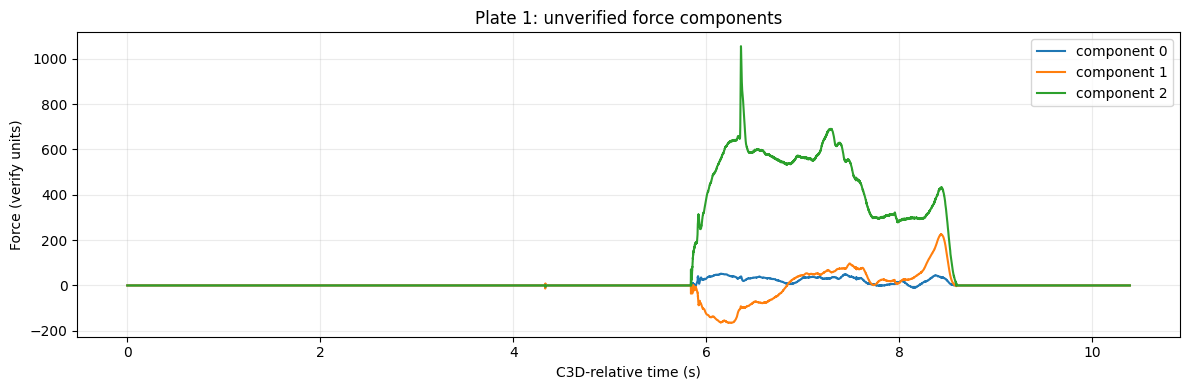

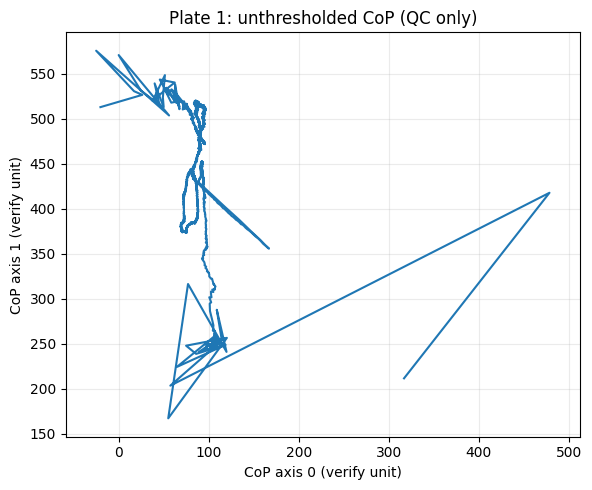

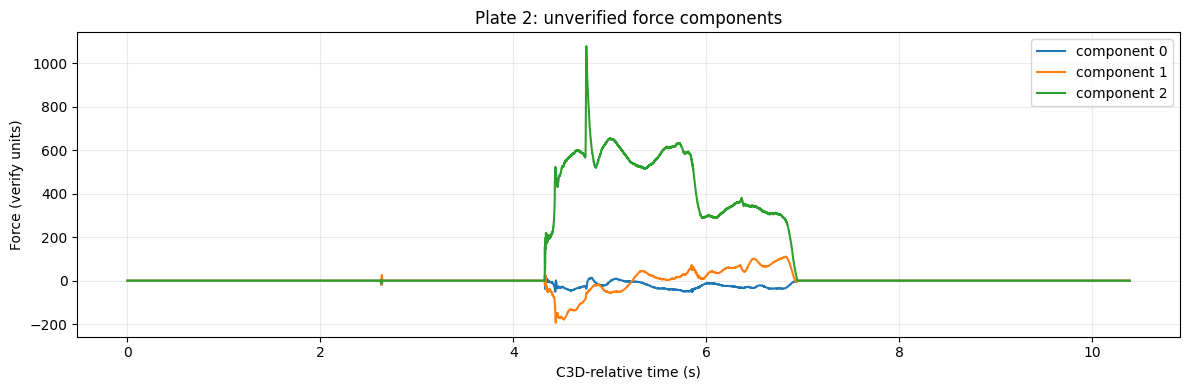

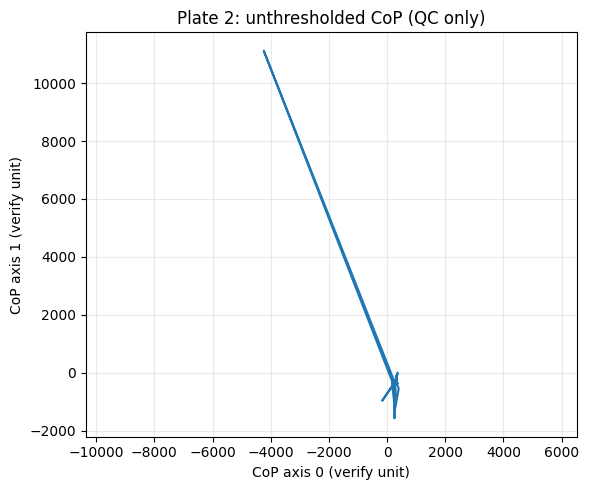

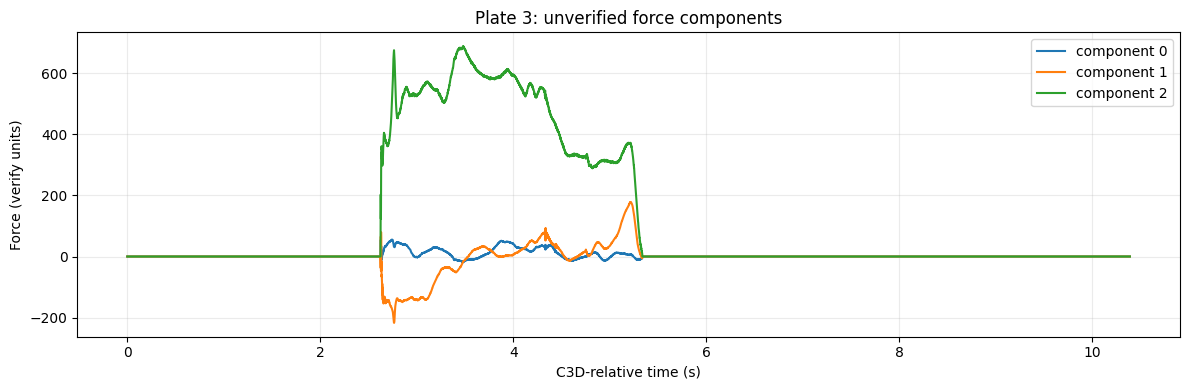

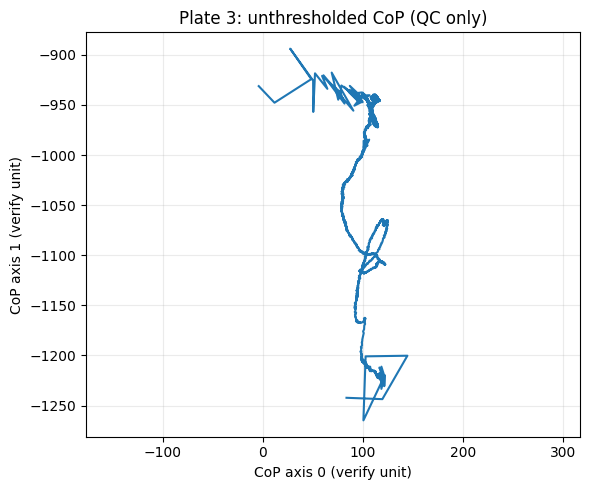

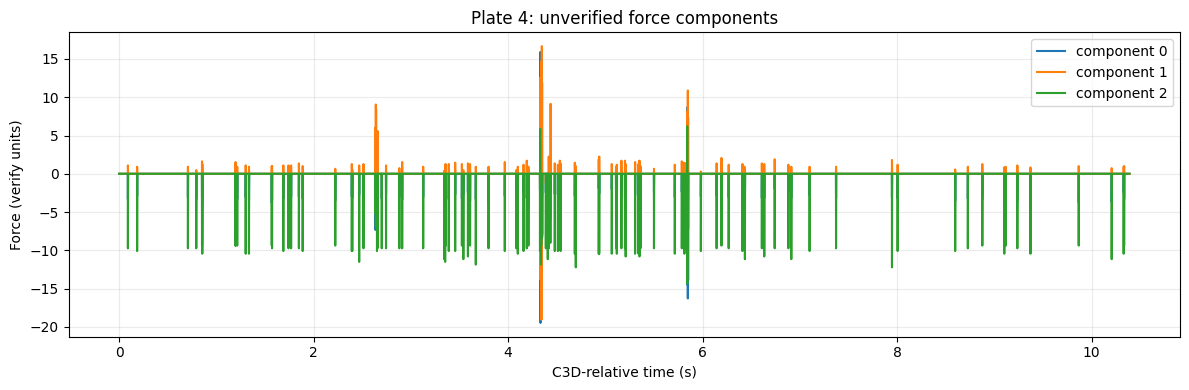

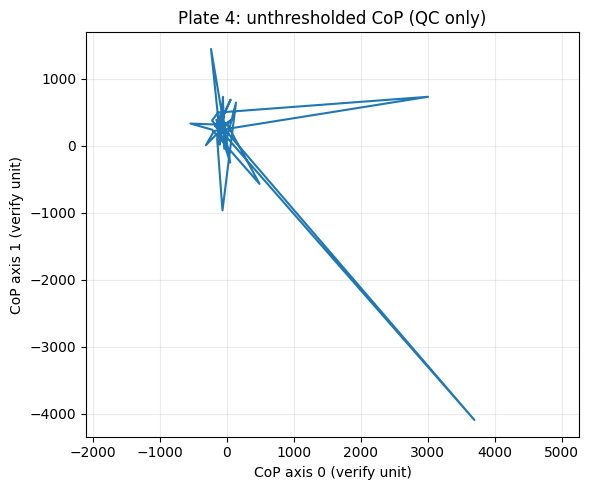

In [42]:
def three_by_n(a):
    a=np.squeeze(np.asarray(a,dtype=float))
    if a.ndim!=2: raise ValueError(f'Unexpected array shape {a.shape}')
    if a.shape[0]==3: return a
    if a.shape[1]==3: return a.T
    raise ValueError(f'No three-axis dimension: {a.shape}')

qc=[]
for i,plate in enumerate(platforms,1):
    f=three_by_n(plate['force'])
    t=np.arange(f.shape[1])/analog_rate
    fig,ax=plt.subplots(figsize=(12,4))
    for j in range(3): ax.plot(t,f[j],label=f'component {j}')
    ax.set(xlabel='C3D-relative time (s)',ylabel='Force (verify units)',title=f'Plate {i}: unverified force components')
    ax.grid(alpha=.25);ax.legend();fig.tight_layout();fig.savefig(OUT/f'plate_{i}_force_components.png',dpi=160);plt.show()
    qc.append(dict(plate=i,n_samples=f.shape[1],duration_s=t[-1]))
    if 'center_of_pressure' in plate:
        cop=three_by_n(plate['center_of_pressure'])
        valid=np.isfinite(cop[:2]).all(axis=0)
        if valid.any():
            fig,ax=plt.subplots(figsize=(6,5));ax.plot(cop[0,valid],cop[1,valid]);ax.axis('equal')
            ax.set(xlabel='CoP axis 0 (verify unit)',ylabel='CoP axis 1 (verify unit)',title=f'Plate {i}: unthresholded CoP (QC only)')
            ax.grid(alpha=.25);fig.tight_layout();fig.savefig(OUT/f'plate_{i}_cop_raw.png',dpi=160);plt.show()
if not platforms: print('No extracted calibrated platforms: inspect metadata and analog channel mapping before proceeding')
pd.DataFrame(qc).to_csv(OUT/'platform_qc.csv',index=False)


Plate 1: force unit = N position unit = mm
Plate 2: force unit = N position unit = mm
Plate 3: force unit = N position unit = mm
Plate 4: force unit = N position unit = mm
Plate 1: peak=1056.0 N, contact samples=2739
Plate 2: peak=1077.5 N, contact samples=2606
Plate 3: peak=687.9 N, contact samples=2705
Plate 4: peak=6.2 N, contact samples=0


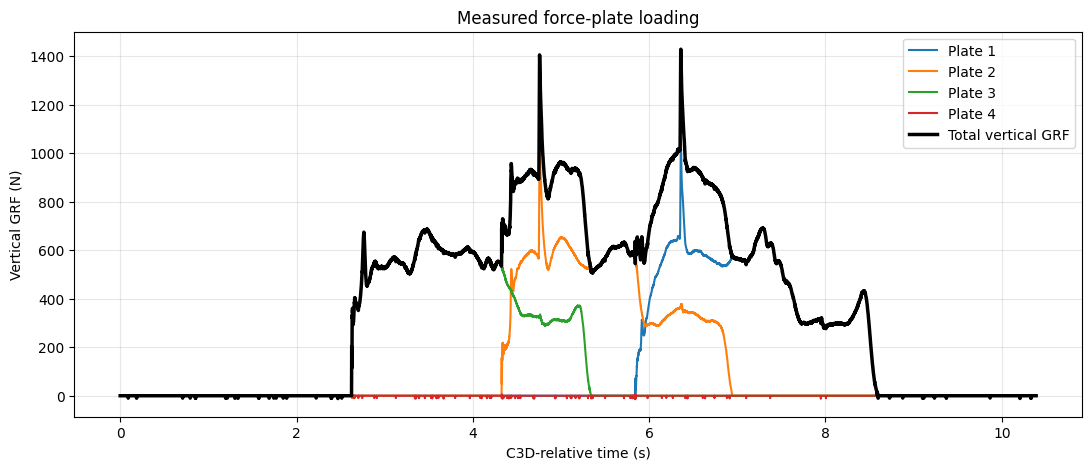

In [43]:
# Provisional threshold; refine after checking noise and units.
CONTACT_THRESHOLD_N = 20.0

# Only proceed after verifying the units and orientation.
for i, plate in enumerate(platforms):
    print(
        f"Plate {i+1}:",
        "force unit =", plate.get("unit_force"),
        "position unit =", plate.get("unit_position"),
    )

vertical_axis = 2
analog_rate = float(c3d["header"]["analogs"]["frame_rate"])

fig, ax = plt.subplots(figsize=(13, 5))

total_fz = None

for i, plate in enumerate(platforms):
    force = np.asarray(plate["force"], dtype=float)
    fz = force[vertical_axis, :]

    t = np.arange(len(fz)) / analog_rate

    if total_fz is None:
        total_fz = np.zeros_like(fz)
    else:
        assert len(total_fz) == len(fz), "Mismatched force sampling"

    total_fz += fz

    contact = fz > CONTACT_THRESHOLD_N
    print(
        f"Plate {i+1}: "
        f"peak={fz.max():.1f} N, "
        f"contact samples={contact.sum()}"
    )

    ax.plot(t, fz, label=f"Plate {i+1}")

ax.plot(
    t, total_fz,
    color="black",
    linewidth=2.5,
    label="Total vertical GRF"
)

ax.set(
    xlabel="C3D-relative time (s)",
    ylabel="Vertical GRF (N)",
    title="Measured force-plate loading"
)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### Visualise COP and force-plate boundaries

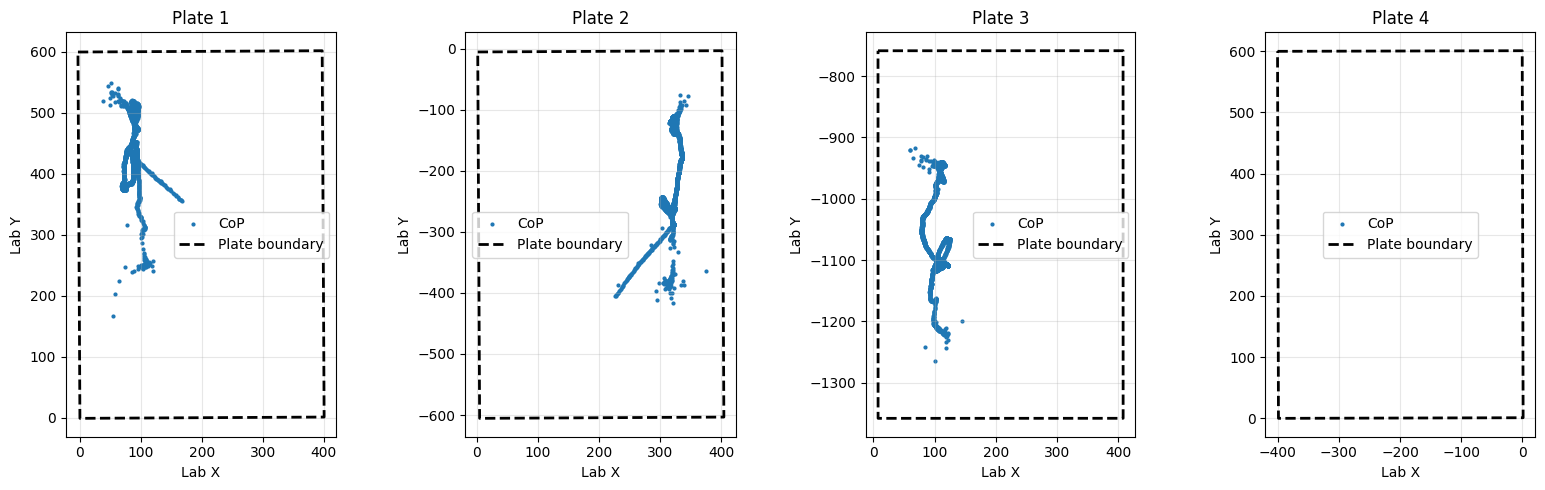

Plate 1: 100.0% of loaded CoP samples inside boundaries
Plate 2: 100.0% of loaded CoP samples inside boundaries
Plate 3: 100.0% of loaded CoP samples inside boundaries
Plate 4: no loaded samples


In [44]:

# Visualize CoP and force-plate boundaries 
fig, axes = plt.subplots(
    1, len(platforms),
    figsize=(4 * len(platforms), 5),
    squeeze=False
)

for i, plate in enumerate(platforms):
    ax = axes[0, i]

    force = np.asarray(plate["force"], dtype=float)
    cop = np.asarray(plate["center_of_pressure"], dtype=float)
    corners = np.asarray(plate["corners"], dtype=float)

    contact = (
        (force[2] > CONTACT_THRESHOLD_N)
        & np.isfinite(cop[0])
        & np.isfinite(cop[1])
    )

    # CoP during loaded periods
    ax.scatter(
        cop[0, contact],
        cop[1, contact],
        s=4,
        label="CoP"
    )

    # Force-platform outline
    xy = corners[:2, :]
    outline = np.column_stack([xy, xy[:, 0]])

    ax.plot(
        outline[0],
        outline[1],
        "k--",
        linewidth=2,
        label="Plate boundary"
    )

    ax.set_title(f"Plate {i+1}")
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Lab X")
    ax.set_ylabel("Lab Y")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

# Calculate percentage of loaded CoP samples inside boundaries
for i, plate in enumerate(platforms):
    force = np.asarray(plate["force"], dtype=float)
    cop = np.asarray(plate["center_of_pressure"], dtype=float)
    corners = np.asarray(plate["corners"], dtype=float)

    contact = (
        (force[2] > CONTACT_THRESHOLD_N)
        & np.isfinite(cop[0])
        & np.isfinite(cop[1])
    )

    if not contact.any():
        print(f"Plate {i+1}: no loaded samples")
        continue

    xy = corners[:2, :]

    inside = (
        (cop[0] >= xy[0].min())
        & (cop[0] <= xy[0].max())
        & (cop[1] >= xy[1].min())
        & (cop[1] <= xy[1].max())
    )

    percentage_inside = 100 * np.mean(inside[contact])

    print(
        f"Plate {i+1}: "
        f"{percentage_inside:.1f}% of loaded CoP samples inside boundaries"
    )

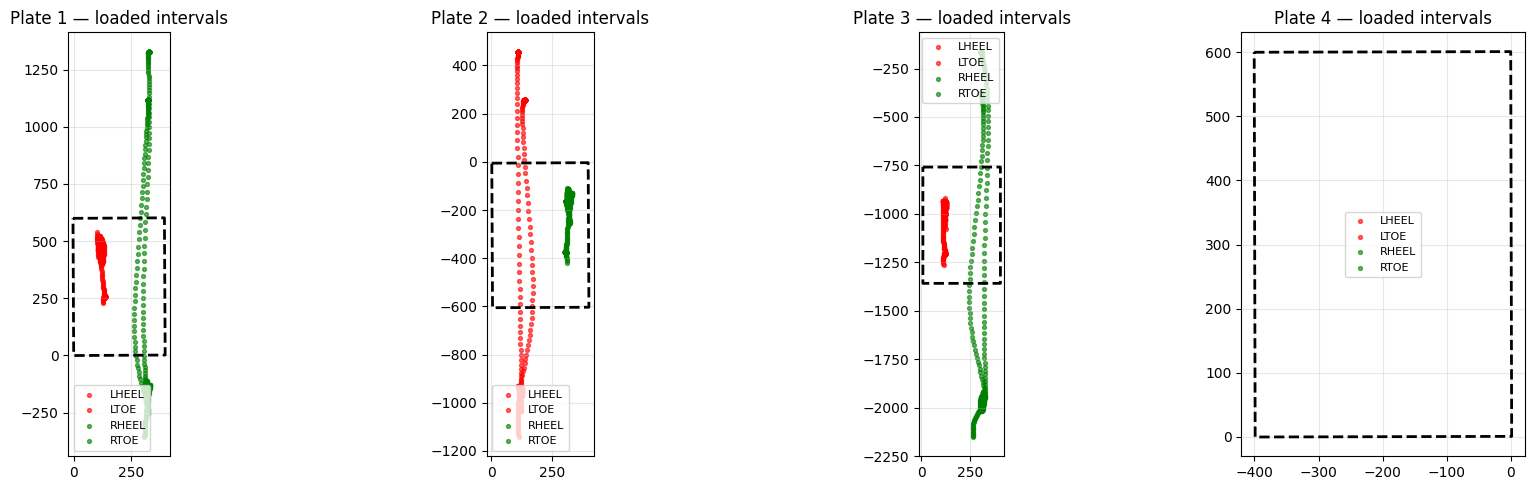

In [45]:
# Plot foot markers during loaded periods, relative to the same recording origin.
point_rate = float(c3d["header"]["points"]["frame_rate"])
analog_rate = float(c3d["header"]["analogs"]["frame_rate"])

labels = list(c3d["parameters"]["POINT"]["LABELS"]["value"])
points = np.asarray(c3d["data"]["points"])

def get_marker_xy(name):
    idx = labels.index(name)
    xyz = points[:3, idx, :].T.astype(float)

    # Invalid markers are excluded.
    residual = points[3, idx, :]
    xyz[residual < 0] = np.nan

    return xyz[:, :2]

marker_names = ["LHEEL", "LTOE", "RHEEL", "RTOE"]
markers = {name: get_marker_xy(name) for name in marker_names}

fig, axes = plt.subplots(
    1, len(platforms),
    figsize=(18, 5),
    squeeze=False
)

for i, plate in enumerate(platforms):
    ax = axes[0, i]

    force = np.asarray(plate["force"], dtype=float)
    corners = np.asarray(plate["corners"], dtype=float)

    fz = force[2]
    force_t = np.arange(len(fz)) / analog_rate

    # Marker-frame time, relative to the same recording origin.
    marker_t = np.arange(points.shape[2]) / point_rate

    # Identify marker frames occurring during plate loading.
    force_at_marker = np.interp(marker_t, force_t, fz)
    contact = force_at_marker > CONTACT_THRESHOLD_N

    xy = corners[:2, :]
    outline = np.column_stack([xy, xy[:, 0]])

    ax.plot(outline[0], outline[1], "k--", linewidth=2)

    for name, color in [
        ("LHEEL", "red"),
        ("LTOE", "red"),
        ("RHEEL", "green"),
        ("RTOE", "green"),
    ]:
        positions = markers[name]
        ax.scatter(
            positions[contact, 0],
            positions[contact, 1],
            s=8,
            color=color,
            alpha=0.6,
            label=name
        )

    ax.set_title(f"Plate {i+1} — loaded intervals")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


## EDA force plates

Analog rate: 1000.0
Number of plates: 4
Plate 1: 1 contact events
Plate 2: 1 contact events
Plate 3: 1 contact events
Plate 4: 0 contact events


,plate_id,start_s,end_s,duration_s,peak_fz_n
0,1,5.844,8.581,2.737,1056.024495
1,2,4.327,6.933,2.606,1077.518560
2,3,2.625,5.330,2.705,687.946877


,plate_id,start_s,end_s,duration_s,peak_fz_n
0,1,5.844,8.581,2.737,1056.024
1,2,4.327,6.933,2.606,1077.519
2,3,2.625,5.330,2.705,687.947


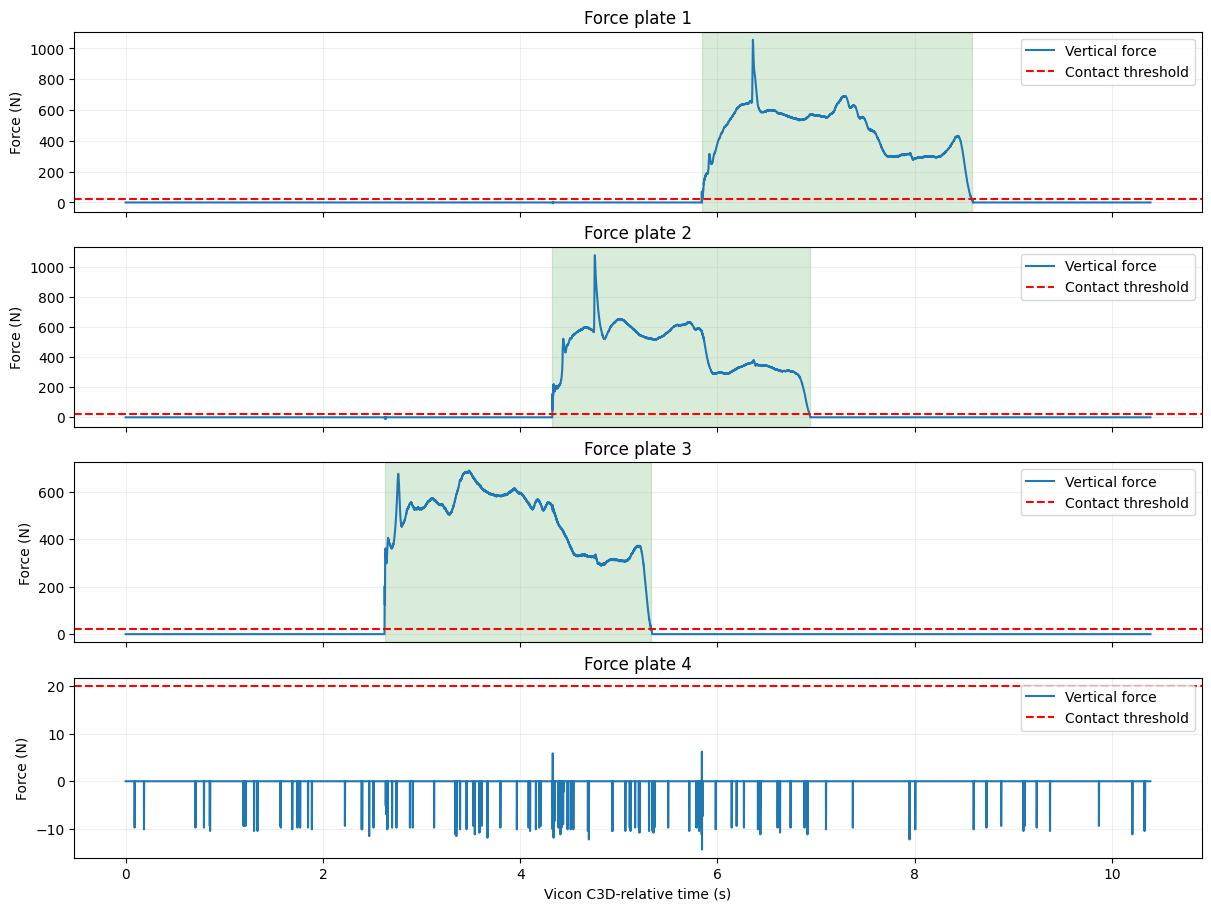

In [46]:
# ----- Load and process force plate data ------
from src.force_plate import (
    load_force_plates,
    detect_contact_events,
)

data = load_force_plates(C3D_PATH)

print(
    "Analog rate:",
    data["analog_rate_hz"]
)

print(
    "Number of plates:",
    len(data["platforms"])
)

# Active force platforms confirmed against data-collection records
ACTIVE_PLATE_IDS = (1, 2, 3)

active_plates = [
    plate for plate in data["platforms"]
    if plate["plate_id"] in ACTIVE_PLATE_IDS
]

all_events = []

for plate in data["platforms"]:
    events = detect_contact_events(
        plate,
        threshold_n=20.0,
        min_duration_s=0.10,
        vertical_axis=2,  # Verify laboratory axis
        vertical_sign=1,  # Verify force sign
    )

    all_events.extend(events)

    print(
        f"Plate {plate['plate_id']}: "
        f"{len(events)} contact events"
    )

events_df = pd.DataFrame(all_events)
display(events_df)


all_events = []

for plate in data["platforms"]:
    events = detect_contact_events(
        plate,
        threshold_n=20.0,
        min_duration_s=0.10,
        vertical_axis=2,
        vertical_sign=1,
    )
    all_events.extend(events)

events_df = pd.DataFrame(all_events)


display(events_df.round(3))

# ----- Visualize contact events on each force plate ------
fig, axes = plt.subplots(
    len(data["platforms"]), 1,
    figsize=(12, 9),
    sharex=True,
    layout="constrained"
)

for ax, plate in zip(axes, data["platforms"]):
    t = plate["time_s"]
    fz = plate["force"][:, 2]

    ax.plot(t, fz, label="Vertical force")
    ax.axhline(
        20,
        color="red",
        linestyle="--",
        label="Contact threshold",
    )

    for event in detect_contact_events(plate):
        ax.axvspan(
            event["start_s"],
            event["end_s"],
            alpha=0.15,
            color="green",
        )

    ax.set_title(f"Force plate {plate['plate_id']}")
    ax.set_ylabel("Force (N)")
    ax.grid(alpha=0.2)
    ax.legend()

axes[-1].set_xlabel("Vicon C3D-relative time (s)")
plt.show()

In [47]:
# Export events_df with exact start/end times, duration, peak force and plate ID. Compare against the shaded intervals

from src.force_plate import detect_contact_events

KINETICS_DIR = (
    ROOT / "results" / SUBJECT / TRIAL / "kinetics"
)
KINETICS_DIR.mkdir(parents=True, exist_ok=True)

all_events = []

for plate in data["platforms"]:
    events = detect_contact_events(
        plate,
        threshold_n=20.0,
        min_duration_s=0.10,
        vertical_axis=2,
        vertical_sign=1,
    )
    all_events.extend(events)

events_df = pd.DataFrame(all_events)

display(events_df.round(3))

events_df.to_csv(
    KINETICS_DIR / "contact_events.csv",
    index=False,
)


,plate_id,start_s,end_s,duration_s,peak_fz_n
0,1,5.844,8.581,2.737,1056.024
1,2,4.327,6.933,2.606,1077.519
2,3,2.625,5.330,2.705,687.947


In [48]:
# Export a QC summary of each force plate's signal characteristics, including baseline statistics and negative-force samples.
qc_rows = []

for plate in data["platforms"]:
    force = np.asarray(plate["force"], dtype=float)
    time = np.asarray(plate["time_s"], dtype=float)

    fz = force[:, 2]

    # Provisional unloaded samples based on the
    # verified positive vertical convention
    unloaded = np.isfinite(fz) & (fz < 20.0)

    qc_rows.append({
        "plate": plate["plate_id"],
        "n_samples": len(fz),
        "duration_s": time[-1] - time[0],
        "max_fz_N": np.nanmax(fz),
        "min_fz_N": np.nanmin(fz),
        "baseline_median_N": np.median(fz[unloaded])
            if unloaded.any() else np.nan,
        "baseline_sd_N": np.std(fz[unloaded])
            if unloaded.any() else np.nan,
        "n_negative_below_5N": int(
            np.count_nonzero(fz < -5)
        ),
    })

qc_df = pd.DataFrame(qc_rows)

display(qc_df.round(3))

qc_df.to_csv(
    KINETICS_DIR / "force_plate_signal_qc.csv",
    index=False,
)


,plate,n_samples,duration_s,max_fz_N,min_fz_N,baseline_median_N,baseline_sd_N,n_negative_below_5N
0,1,10390,10.389,1056.024,-5.831,0.0,0.549,1
1,2,10390,10.389,1077.519,-9.623,0.0,0.514,5
2,3,10390,10.389,687.947,0.000,0.0,0.423,0
3,4,10390,10.389,6.219,-14.343,0.0,1.063,121


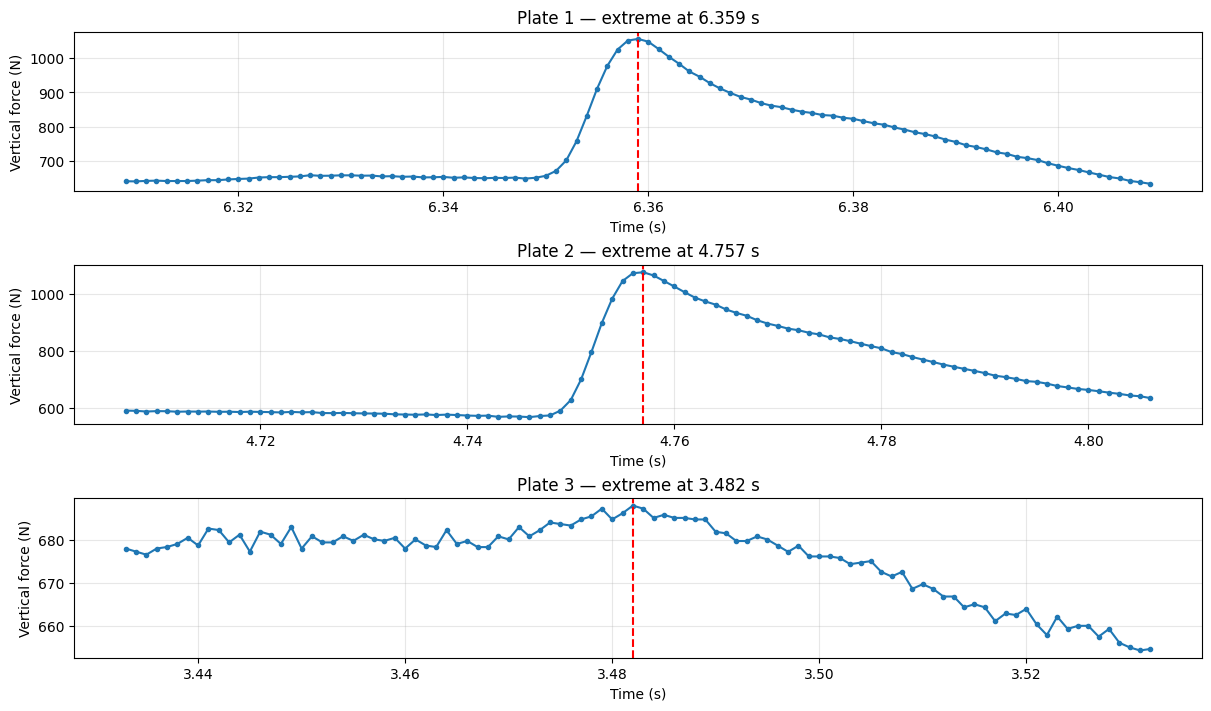

In [49]:

fig, axes = plt.subplots(
    3, 1, figsize=(12, 7),
    layout="constrained"
)

for ax, plate_id in zip(axes, (1, 2, 3)):
    plate = data["platforms"][plate_id - 1]

    t = plate["time_s"]
    fz = plate["force"][:, 2]

    if plate_id == 1 or plate_id == 2 or plate_id == 3:
        idx = np.nanargmax(fz)
    else:
        idx = np.nanargmin(fz)

    # Show 50 ms on either side of the extreme sample
    mask = (t >= t[idx] - 0.05) & (t <= t[idx] + 0.05)

    ax.plot(t[mask], fz[mask], ".-")
    ax.axvline(t[idx], color="red", linestyle="--")

    ax.set_title(
        f"Plate {plate_id} — extreme at {t[idx]:.3f} s"
    )
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Vertical force (N)")
    ax.grid(alpha=0.3)

plt.show()

## Physics informed kinetics estimation

In [50]:
# Extract foot markers and their original Vicon timestamps

point_rate = float(c3d["header"]["points"]["frame_rate"])
points = np.asarray(c3d["data"]["points"])

labels = [
    label.strip()
    for label in c3d["parameters"]["POINT"]["LABELS"]["value"]
]

marker_time_s = np.arange(points.shape[2]) / point_rate

def get_marker_xyz(name):
    if name not in labels:
        raise KeyError(f"Missing Vicon marker: {name}")

    idx = labels.index(name)
    xyz = points[:3, idx, :].T.astype(float).copy()

    # C3D negative residual = invalid marker
    residual = points[3, idx, :]
    xyz[residual < 0] = np.nan

    return xyz

foot_markers = {
    name: get_marker_xyz(name)
    for name in ("LHEEL", "LTOE", "RHEEL", "RTOE")
}

print("Marker frames:", len(marker_time_s))
print("Sampling frequency:", point_rate)

Marker frames: 1039
Sampling frequency: 100.0


In [51]:

from matplotlib.path import Path as MplPath

def points_inside_plate(xy, corners):
    """
    Test whether XY positions lie inside the
    four-corner force-plate footprint.
    """
    xy = np.asarray(xy, dtype=float)
    corners = np.asarray(corners, dtype=float)

    if corners.shape != (3, 4):
        raise ValueError(
            f"Expected corners (3, 4), got {corners.shape}"
        )

    polygon = corners[:2].T

    center = polygon.mean(axis=0)

    angles = np.arctan2(
        polygon[:, 1] - center[1],
        polygon[:, 0] - center[0]
    )

    polygon = polygon[np.argsort(angles)]

    # Explicitly repeat the first corner to close the polygon
    polygon = np.vstack([polygon, polygon[0]])

    valid = np.isfinite(xy).all(axis=1)
    inside = np.zeros(len(xy), dtype=bool)

    inside[valid] = MplPath(
        polygon
    ).contains_points(xy[valid])

    return inside


In [52]:
def assign_foot_contacts_spatial(
    contact_events,
    platforms,
    foot_markers,
    marker_time_s,
    threshold=0.75, # 75% of valid marker frames must be inside the plate
):
    """
    Assign force-plate contact events using Vicon foot positions.

    threshold:
        Minimum fraction of valid marker frames during which
        a foot must lie inside the corresponding plate.

    Ambiguous assignments remain unresolved.
    """

    platform_lookup = {
        plate["plate_id"]: plate
        for plate in platforms
    }

    results = []

    for event in contact_events:
        plate_id = event["plate_id"]
        plate = platform_lookup[plate_id]

        start_s = event["start_s"]
        end_s = event["end_s"]

        mask = (
            (marker_time_s >= start_s)
            & (marker_time_s < end_s)
        )

        row = {
            **event,
            "left_fraction_inside": np.nan,
            "right_fraction_inside": np.nan,
            "assigned_foot": "unresolved",
        }

        if not mask.any():
            results.append(row)
            continue

        fractions = {}

        for side in ("L", "R"):
            heel = foot_markers[f"{side}HEEL"]
            toe = foot_markers[f"{side}TOE"]

            foot_center = 0.5 * (heel + toe)
            foot_xy = foot_center[mask, :2]

            valid = np.isfinite(foot_xy).all(axis=1)

            if not valid.any():
                fractions[side] = np.nan
                continue

            inside = points_inside_plate(
                foot_xy[valid],
                plate["corners"],
            )

            fractions[side] = float(np.mean(inside))

        row["left_fraction_inside"] = fractions.get("L", np.nan)
        row["right_fraction_inside"] = fractions.get("R", np.nan)

        candidates = [
            side
            for side, fraction in fractions.items()
            if np.isfinite(fraction) and fraction >= threshold
        ]

        if len(candidates) == 1:
            row["assigned_foot"] = candidates[0]
        elif len(candidates) == 2:
            row["assigned_foot"] = "ambiguous"

        results.append(row)

    return pd.DataFrame(results)

In [53]:

# ----- Assign foot contacts to force-plate events using spatial QC ------
active_events = [
    event
    for event in all_events
    if event["plate_id"] in ACTIVE_PLATE_IDS
]

assignment_df = assign_foot_contacts_spatial(
    contact_events=active_events,
    platforms=active_plates,
    foot_markers=foot_markers,
    marker_time_s=marker_time_s,
    threshold=0.75,
)

display(
    assignment_df[
        [
            "plate_id",
            "start_s",
            "end_s",
            "left_fraction_inside",
            "right_fraction_inside",
            "assigned_foot",
        ]
    ].round(3)
)

assignment_df.to_csv(
    KINETICS_DIR / "foot_plate_assignments.csv",
    index=False,
)

,plate_id,start_s,end_s,left_fraction_inside,right_fraction_inside,assigned_foot
0,1,5.844,8.581,1.000,0.077,L
1,2,4.327,6.933,0.073,1.000,R
2,3,2.625,5.330,1.000,0.059,L


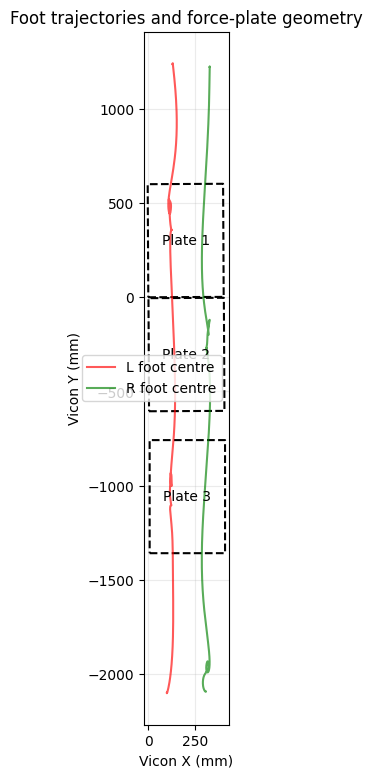

In [54]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 9))

for plate in active_plates:
    corners = np.asarray(plate["corners"])
    polygon = corners[:2].T

    center = polygon.mean(axis=0)

    angles = np.arctan2(
        polygon[:, 1] - center[1],
        polygon[:, 0] - center[0]
    )

    polygon = polygon[np.argsort(angles)]
    polygon = np.vstack([polygon, polygon[0]])

    ax.plot(
        polygon[:, 0],
        polygon[:, 1],
        "k--",
        linewidth=1.5
    )

    ax.text(
        center[0],
        center[1],
        f"Plate {plate['plate_id']}",
        ha="center",
        va="center"
    )

for side, color in (("L", "red"), ("R", "green")):
    heel = foot_markers[f"{side}HEEL"]
    toe = foot_markers[f"{side}TOE"]

    center = 0.5 * (heel + toe)

    ax.plot(
        center[:, 0],
        center[:, 1],
        color=color,
        alpha=0.65,
        label=f"{side} foot centre"
    )

ax.set_aspect("equal")
ax.set_xlabel("Vicon X (mm)")
ax.set_ylabel("Vicon Y (mm)")
ax.set_title("Foot trajectories and force-plate geometry")
ax.grid(alpha=0.25)
ax.legend()

plt.show()

In [55]:
# ----- Export measured external loads for inverse dynamics ------
OUT_DIR = (
    ROOT / "results" / SUBJECT / TRIAL / "kinetics"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

rows = []

for plate in active_plates:
    n = len(plate["time_s"])

    force = np.asarray(plate["force"], dtype=float)
    cop = np.asarray(plate["cop"], dtype=float)
    moment = np.asarray(plate["moment"], dtype=float)
    free = np.asarray(plate["free_moment"], dtype=float)

    if not all(
        arr.shape == (n, 3)
        for arr in (force, cop, moment, free)
    ):
        raise ValueError(
            f"Invalid array dimensions: plate {plate['plate_id']}"
        )

    # Only convert when these source units are verified
    if str(plate["unit_force"]) != "N":
        raise ValueError("Force units require verification")
    if str(plate["unit_position"]) != "mm":
        raise ValueError("Position units require verification")
    if str(plate["unit_moment"]) != "Nmm":
        raise ValueError("Moment units require verification")

    table = pd.DataFrame({
        "plate_id": plate["plate_id"],
        "time_s": plate["time_s"],
        "Fx_N": force[:, 0],
        "Fy_N": force[:, 1],
        "Fz_N": force[:, 2],
        "CoP_x_m": cop[:, 0] / 1000,
        "CoP_y_m": cop[:, 1] / 1000,
        "CoP_z_m": cop[:, 2] / 1000,
        "Mx_Nm": moment[:, 0] / 1000,
        "My_Nm": moment[:, 1] / 1000,
        "Mz_Nm": moment[:, 2] / 1000,
        "Tz_x_Nm": free[:, 0] / 1000,
        "Tz_y_Nm": free[:, 1] / 1000,
        "Tz_z_Nm": free[:, 2] / 1000,
    })

    rows.append(table)

external_loads = pd.concat(rows, ignore_index=True)

output_path = OUT_DIR / "measured_external_loads.csv"
external_loads.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Rows:", len(external_loads))
display(external_loads.head())


Saved: /Users/thomasjohnson/markerless/markerless_sam/results/S11/lunge_01/kinetics/measured_external_loads.csv
Rows: 31170


,plate_id,time_s,Fx_N,Fy_N,Fz_N,CoP_x_m,CoP_y_m,CoP_z_m,Mx_Nm,My_Nm,Mz_Nm,Tz_x_Nm,Tz_y_Nm,Tz_z_Nm
0,1,0.000,0.0,0.0,0.0,NaN,NaN,NaN,0.0,0.0,-0.0,NaN,NaN,NaN
1,1,0.001,0.0,0.0,0.0,NaN,NaN,NaN,0.0,0.0,-0.0,NaN,NaN,NaN
2,1,0.002,0.0,0.0,0.0,NaN,NaN,NaN,0.0,0.0,-0.0,NaN,NaN,NaN
3,1,0.003,0.0,0.0,0.0,NaN,NaN,NaN,0.0,0.0,-0.0,NaN,NaN,NaN
4,1,0.004,0.0,0.0,0.0,NaN,NaN,NaN,0.0,0.0,-0.0,NaN,NaN,NaN


In [56]:
import ezc3d

c3d = ezc3d.c3d(str(C3D_PATH))

labels = [
    label.strip()
    for label in c3d["parameters"]["POINT"]["LABELS"]["value"]
]

points = np.asarray(c3d["data"]["points"], dtype=float)

point_rate = float(c3d["header"]["points"]["frame_rate"])

vicon_time_s = np.arange(points.shape[2]) / point_rate

def get_vicon_marker(name):
    idx = labels.index(name)
    marker = points[:3, idx, :].T.copy()
    marker[points[3, idx, :] < 0] = np.nan
    return marker

# Midpoint between anterior pelvic markers
lasis = get_vicon_marker("LASI")
rasis = get_vicon_marker("RASI")

vicon_pelvis = (lasis + rasis) / 2

# Convert marker coordinates from mm to metres,
# assuming the C3D POINT units are confirmed as mm.
vicon_pelvis_m = vicon_pelvis / 1000

print(
    "Vicon pelvis coordinate ranges (m):",
    np.nanmax(vicon_pelvis_m, axis=0)
    - np.nanmin(vicon_pelvis_m, axis=0)
)

Vicon pelvis coordinate ranges (m): [0.13913974 3.3489826  0.44900925]


## Scientific gates

- Verify calibrated plate forces, vertical sign and units against lab configuration; define contact threshold and exclude CoP outside contact.
- Confirm analog/marker clock origin within C3D; align SAM video-derived timestamps to this clock using the **camera-specific reviewed** synchronization. Never shift Vicon data twice.
- Determine which foot contacts which plate and obtain body mass/height.
- Verify SAM root trajectory, absolute scale, coordinate frame, full-body markers/mesh and actual video timestamps before differentiating COM twice.
- Proceed to measured GRF and CoP, then estimated total GRF, and only then bilateral inverse dynamics with contact and inertial assumptions.
